# ÉquiAlgo: production monitoring demo (`monitoring_demo.ipynb`)

`GOVERNANCE.md` sets thresholds for what to watch once the model is live. This notebook shows that plan
is **running code**, not just a document: `monitoring.py` checks every scoring batch and returns
**OK**, **ALERT** (a person reviews the batch before decisions go out) or **STOP** (decisions are held and the
manual committee takes over).

We run it on the real evaluation batch, then on four realistic failure scenarios, and check that each one
trips the right alarm and nothing else.

| Scenario | What goes wrong | Expected alarm |
|---|---|---|
| A. Normal batch | nothing | none |
| B. Old model redeployed | someone ships the biased random forest again | fairness STOP |
| C. Hours gaming | a quarter of applicants inflate hours worked by 6 per week | drift ALERT on hours |
| D. Population shift | remote applications double | drift ALERT on region mix, fairness still OK |
| E. Fixed cutoff | last year's score threshold reused on a stronger cohort | budget STOP |

Run after `model_corrige.ipynb`. Shared code: `equialgo.py`, `monitoring.py`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

import equialgo as eq
import monitoring as mon

pd.set_option("display.precision", 3)
hist, cand = eq.load()
final = eq.BiasAwareModel().fit(hist, hist.decision_octroi)

def decide(batch):
    # Production rule: rank by the final merit score and grant the top 41% of the batch.
    return eq.select_top(final.final_score(batch), eq.FINAL_RATE)

scenarios = {}

## A. Normal batch: the 4,000 evaluation applicants

In [2]:
scenarios["A. Normal batch"] = mon.check_batch(cand, decide(cand), hist)
print("Batch status:", mon.overall_status(scenarios["A. Normal batch"]))
scenarios["A. Normal batch"]

Batch status: OK


,indicator,value,status,rule
0,Grant rate,0.410,OK,"green 38-42%, budget 36-44%"
1,Parity gap (centre - remote),-0.002,OK,"|gap| alert > 0.05, stop > 0.10"
2,Worst region vs overall (Gaspesie-Iles-de-la-M...,0.015,OK,"alert > 5 pts, stop > 10 pts"
3,Worst region gap within an income quartile,0.021,OK,"alert > 0.05, stop > 0.10"
4,Drift (PSI): R score,0.003,OK,"alert > 0.10, stop > 0.25"
5,Drift (PSI): hours worked,0.003,OK,"alert > 0.10, stop > 0.25"
6,Drift (PSI): family income,0.005,OK,"alert > 0.10, stop > 0.25"
7,Drift (PSI): distance,0.001,OK,"alert > 0.10, stop > 0.25"
8,Drift (PSI): region mix,0.001,OK,"alert > 0.10, stop > 0.25"


## B. The old model is redeployed

The biased production random forest is put back in service by mistake (or retrained on committee labels).

In [3]:
CAT = ["programme_etudes", "region_administrative", "code_postal_3"]
A = pd.get_dummies(hist.drop(columns=["id_candidat", "decision_octroi"]), columns=CAT)
B = pd.get_dummies(cand.drop(columns=["id_candidat"]), columns=CAT).reindex(columns=A.columns, fill_value=0)
old_model = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1).fit(A, hist.decision_octroi)
scenarios["B. Old model redeployed"] = mon.check_batch(cand, old_model.predict(B), hist)
print("Batch status:", mon.overall_status(scenarios["B. Old model redeployed"]))
scenarios["B. Old model redeployed"]

Batch status: STOP


,indicator,value,status,rule
0,Grant rate,0.391,OK,"green 38-42%, budget 36-44%"
1,Parity gap (centre - remote),0.190,STOP,"|gap| alert > 0.05, stop > 0.10"
2,Worst region vs overall (Cote-Nord),0.130,STOP,"alert > 5 pts, stop > 10 pts"
3,Worst region gap within an income quartile,0.196,STOP,"alert > 0.05, stop > 0.10"
4,Drift (PSI): R score,0.003,OK,"alert > 0.10, stop > 0.25"
5,Drift (PSI): hours worked,0.003,OK,"alert > 0.10, stop > 0.25"
6,Drift (PSI): family income,0.005,OK,"alert > 0.10, stop > 0.25"
7,Drift (PSI): distance,0.001,OK,"alert > 0.10, stop > 0.25"
8,Drift (PSI): region mix,0.001,OK,"alert > 0.10, stop > 0.25"


The grant rate looks normal, so a budget-only dashboard would miss this. The fairness indicators stop it.

## C. Hours gaming

Hours worked now count in the score, so applicants have a reason to overstate them. A quarter of the batch
adds 6 hours per week.

In [4]:
rng = np.random.default_rng(0)
gamed = cand.copy()
cheaters = rng.random(len(gamed)) < 0.25
gamed.loc[cheaters, "heures_travail_semaine"] += 6
scenarios["C. Hours gaming"] = mon.check_batch(gamed, decide(gamed), hist)
print("Batch status:", mon.overall_status(scenarios["C. Hours gaming"]))
honest = decide(cand)
print(f"Honest applicants pushed out by the cheaters: {int(((honest == 1) & (decide(gamed) == 0) & ~cheaters).sum())}")
scenarios["C. Hours gaming"]

Batch status: ALERT
Honest applicants pushed out by the cheaters: 103


,indicator,value,status,rule
0,Grant rate,0.410,OK,"green 38-42%, budget 36-44%"
1,Parity gap (centre - remote),-0.011,OK,"|gap| alert > 0.05, stop > 0.10"
2,Worst region vs overall (Gaspesie-Iles-de-la-M...,0.021,OK,"alert > 5 pts, stop > 10 pts"
3,Worst region gap within an income quartile,0.042,OK,"alert > 0.05, stop > 0.10"
4,Drift (PSI): R score,0.003,OK,"alert > 0.10, stop > 0.25"
5,Drift (PSI): hours worked,0.134,ALERT,"alert > 0.10, stop > 0.25"
6,Drift (PSI): family income,0.005,OK,"alert > 0.10, stop > 0.25"
7,Drift (PSI): distance,0.001,OK,"alert > 0.10, stop > 0.25"
8,Drift (PSI): region mix,0.001,OK,"alert > 0.10, stop > 0.25"


Fairness between regions is untouched, but the hours distribution shifts. The alert sends reviewers to check
documents (pay stubs, employer letters), which is the control `GOVERNANCE.md` asks for.

## D. Population shift: remote applications double

In [5]:
remote = eq.is_remote(cand) == 1
weights = np.where(remote, 2.0, 1.0)
shifted = cand.iloc[rng.choice(len(cand), len(cand), p=weights / weights.sum())].reset_index(drop=True)
scenarios["D. Population shift"] = mon.check_batch(shifted, decide(shifted), hist)
print("Batch status:", mon.overall_status(scenarios["D. Population shift"]))
scenarios["D. Population shift"]

Batch status: ALERT


,indicator,value,status,rule
0,Grant rate,0.410,OK,"green 38-42%, budget 36-44%"
1,Parity gap (centre - remote),0.027,OK,"|gap| alert > 0.05, stop > 0.10"
2,Worst region vs overall (Capitale-Nationale),0.028,OK,"alert > 5 pts, stop > 10 pts"
3,Worst region gap within an income quartile,0.048,OK,"alert > 0.05, stop > 0.10"
4,Drift (PSI): R score,0.004,OK,"alert > 0.10, stop > 0.25"
5,Drift (PSI): hours worked,0.056,OK,"alert > 0.10, stop > 0.25"
6,Drift (PSI): family income,0.013,OK,"alert > 0.10, stop > 0.25"
7,Drift (PSI): distance,0.152,ALERT,"alert > 0.10, stop > 0.25"
8,Drift (PSI): region mix,0.156,ALERT,"alert > 0.10, stop > 0.25"


The monitor flags the change in applicant mix, but every fairness indicator stays green: the model treats a
larger remote population correctly. A reviewer confirms the shift is real (for example, a recruitment
campaign in Gaspésie) and releases the batch.

## E. A fixed cutoff is reused on a stronger cohort

The rule is "top 41% of each batch". If someone instead reuses last year's score threshold and the new
cohort has R scores one point higher, far more awards are granted than the budget allows.

In [6]:
last_year_cutoff = np.quantile(final.final_score(hist), 1 - eq.FINAL_RATE)
stronger = cand.copy()
stronger["cote_r_equivalent"] += 1.0
fixed_cutoff = (final.final_score(stronger) >= last_year_cutoff).astype(int)
scenarios["E. Fixed cutoff"] = mon.check_batch(stronger, fixed_cutoff, hist)
print("Batch status:", mon.overall_status(scenarios["E. Fixed cutoff"]))
scenarios["E. Fixed cutoff"]

Batch status: STOP


,indicator,value,status,rule
0,Grant rate,0.552,STOP,"green 38-42%, budget 36-44%"
1,Parity gap (centre - remote),0.008,OK,"|gap| alert > 0.05, stop > 0.10"
2,Worst region vs overall (Cote-Nord),0.031,OK,"alert > 5 pts, stop > 10 pts"
3,Worst region gap within an income quartile,0.023,OK,"alert > 0.05, stop > 0.10"
4,Drift (PSI): R score,0.115,ALERT,"alert > 0.10, stop > 0.25"
5,Drift (PSI): hours worked,0.003,OK,"alert > 0.10, stop > 0.25"
6,Drift (PSI): family income,0.005,OK,"alert > 0.10, stop > 0.25"
7,Drift (PSI): distance,0.001,OK,"alert > 0.10, stop > 0.25"
8,Drift (PSI): region mix,0.001,OK,"alert > 0.10, stop > 0.25"


## Dashboard

One row per scenario, one column per indicator. Each cell shows the status word and the value, so the
status never depends on colour alone.

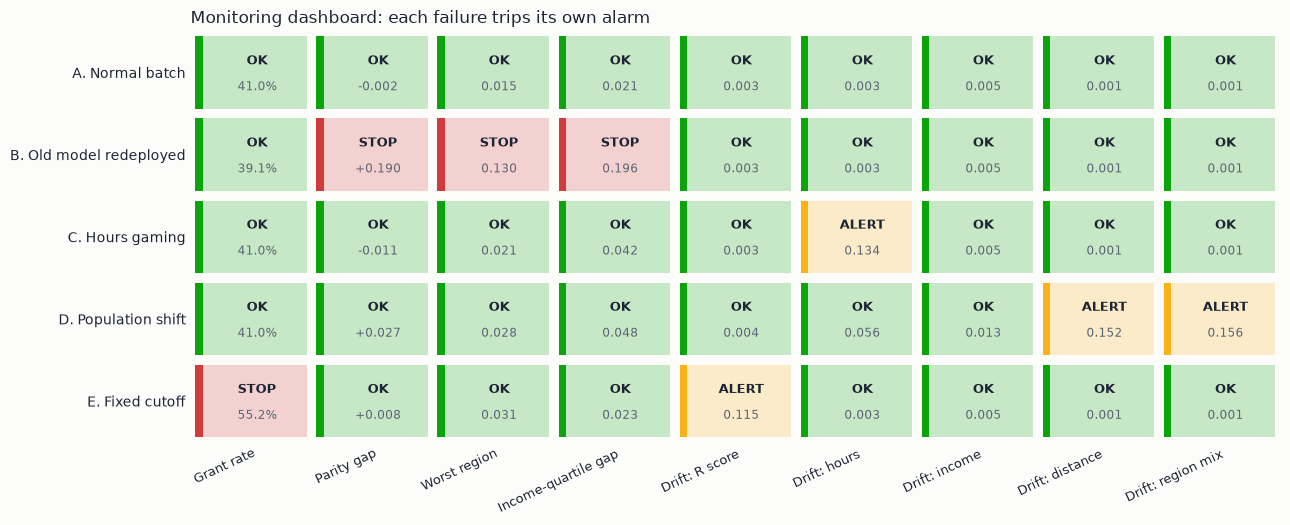

,Grant rate,Parity gap,Worst region,Income-quartile gap,Drift: R score,Drift: hours,Drift: income,Drift: distance,Drift: region mix,batch
A. Normal batch,OK,OK,OK,OK,OK,OK,OK,OK,OK,OK
B. Old model redeployed,OK,STOP,STOP,STOP,OK,OK,OK,OK,OK,STOP
C. Hours gaming,OK,OK,OK,OK,OK,ALERT,OK,OK,OK,ALERT
D. Population shift,OK,OK,OK,OK,OK,OK,OK,ALERT,ALERT,ALERT
E. Fixed cutoff,STOP,OK,OK,OK,ALERT,OK,OK,OK,OK,STOP


In [7]:
STATUS_FILL = {mon.OK: "#0ca30c", mon.ALERT: "#fab219", mon.STOP: "#d03b3b"}
SHORT = ["Grant rate", "Parity gap", "Worst region", "Income-quartile gap",
         "Drift: R score", "Drift: hours", "Drift: income", "Drift: distance", "Drift: region mix"]

names = list(scenarios)
fig, ax = plt.subplots(figsize=(13, 0.75 * len(names) + 1.6))
fig.patch.set_facecolor("#fcfcfb"); ax.set_facecolor("#fcfcfb")
for i, name in enumerate(names):
    rep = scenarios[name].reset_index(drop=True)
    for j in range(len(SHORT)):
        status, value = rep.loc[j, "status"], rep.loc[j, "value"]
        ax.add_patch(plt.Rectangle((j + 0.04, i + 0.06), 0.92, 0.88, color=STATUS_FILL[status], alpha=0.22, lw=0))
        ax.add_patch(plt.Rectangle((j + 0.04, i + 0.06), 0.06, 0.88, color=STATUS_FILL[status], lw=0))
        text = f"{value:.1%}" if j == 0 else f"{value:+.3f}" if j == 1 else f"{value:.3f}"
        ax.text(j + 0.55, i + 0.36, status, ha="center", va="center", fontsize=9.5, weight="bold", color="#1d2433")
        ax.text(j + 0.55, i + 0.68, text, ha="center", va="center", fontsize=8.5, color="#5b6475")
ax.set_xlim(0, len(SHORT)); ax.set_ylim(len(names), 0)
ax.set_xticks(np.arange(len(SHORT)) + 0.55); ax.set_xticklabels(SHORT, rotation=25, ha="right", fontsize=9, color="#1d2433")
ax.set_yticks(np.arange(len(names)) + 0.5); ax.set_yticklabels(names, fontsize=10, color="#1d2433")
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Monitoring dashboard: each failure trips its own alarm", loc="left", fontsize=12, color="#1d2433")
plt.tight_layout(); plt.savefig("figures/monitoring_dashboard.png", bbox_inches="tight", facecolor="#fcfcfb"); plt.show()

summary = pd.DataFrame({name: rep.set_index("indicator")["status"].to_numpy() for name, rep in scenarios.items()},
                       index=SHORT).T
summary["batch"] = [mon.overall_status(scenarios[n]) for n in names]
summary

## What this shows

- **Each failure trips its own alarm and only that alarm.** The old biased model is stopped by fairness
  indicators, gaming and population shifts raise drift alerts, and a broken budget rule is stopped by the grant rate.
- **A budget-only dashboard would have missed scenario B.** The biased model spends the budget normally.
- **Not covered per batch:** the equal-opportunity gap needs outcome data (first-year results, blind-panel reviews),
  so it is computed yearly (`GOVERNANCE.md`, section 3.2).
- **Thresholds are starting points.** With small batches, sampling noise alone can move a region's rate by a few
  points. The bands should be recalibrated on the first months of real batches.